In [1]:
pip install split-folders

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install livelossplot

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install opencv-python imageio

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.0.2-cp39-cp39-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (19.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scipy 1.11.4 requires numpy<1.28.0,>=1.21.6, but you have numpy 2.0.2 which is incompatible.
scikit-learn 1.3.2 requires numpy<2.0,>=1.17.3, but you have numpy 2.0.2 which is incompatible.
karateclub 1.3.3 requires numpy<1.23.0, but you have numpy 2.0.2 which is incompatible.
karateclub 1.3.3 requires pandas<=1.3.5, but you have pandas 2.3.3 which is incompatible.
Note: you may need 

In [4]:
pip install --upgrade keras tensorflow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [5]:
!pip install "numpy<2"

Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.4-cp39-cp39-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.
karateclub 1.3.3 requires numpy<1.23.0, but you have numpy 1.26.4 which is incompatible.
karateclub 1.3.3 requires pandas<=1.3.5, but you have pandas 2.3.3 which is incompatible.


In [1]:
import numpy as np
import pandas as pd
import glob
from tqdm import tqdm
import cv2
import matplotlib.pyplot as plt
import os
import imageio.v2 as iio
import shutil
from livelossplot import PlotLossesKeras
from tqdm import tqdm
import keras
import tensorflow as tf

2026-08-06 11:35:19.844681: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import splitfolders

In [3]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [11]:
import zipfile

zip_path = "TrOCR_KAN/archive.zip"
extract_to = "TrOCR_KAN/data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_to)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [67]:
import zipfile

zip_path = "/jupyter/aswin.vs/TrOCR_KAN/fixed_data.zip"
extract_to = "/jupyter/aswin.vs/TrOCR_KAN/fixed"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_to)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [4]:
d_m_path="/jupyter/aswin.vs/TrOCR_KAN/fixed/fixed_data"

In [5]:
letters=glob.glob(d_m_path+"/*")
letters=sorted(letters)[1:]
len(letters)

119

In [6]:
import os

os.chdir("/jupyter/aswin.vs/TrOCR_KAN")
print(os.getcwd())

/jupyter/aswin.vs/TrOCR_KAN


In [7]:
curnt_dir="/jupyter/aswin.vs/TrOCR_KAN"

In [8]:
!mkdir "dataset/"

mkdir: cannot create directory ‘dataset/’: File exists


In [74]:
for letter in tqdm(letters):
    imgs=glob.glob(letter+"/*.png")
    path="/jupyter/aswin.vs/TrOCR_KAN/dataset/"+str(letters.index(letter))
    os.mkdir(path)
    os.chdir(path)
    for img_name in imgs:
        img = cv2.imread(img_name,flags=cv2.IMREAD_UNCHANGED)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2BGRA)
        img=img[:,:,3]
        img=img/255.0
        img=np.where(img>0.5,1,0)
        if len(np.unique(img))<2:
            continue
        cv2.imwrite(str(imgs.index(img_name))+".png",img)
os.chdir(curnt_dir)

100%|██████████| 119/119 [00:07<00:00, 14.88it/s]


In [9]:
import glob
import os

print("Current directory:", os.getcwd())

letters = sorted(glob.glob("fixed/fixed_data/*"))
print("Number of folders found:", len(letters))

print("Last 10 folders:")
print(letters[-10:])

Current directory: /jupyter/aswin.vs/TrOCR_KAN
Number of folders found: 120
Last 10 folders:
['fixed/fixed_data/ീ', 'fixed/fixed_data/ു', 'fixed/fixed_data/ൂ', 'fixed/fixed_data/ൃ', 'fixed/fixed_data/െ', 'fixed/fixed_data/്', 'fixed/fixed_data/്യ', 'fixed/fixed_data/്ര', 'fixed/fixed_data/്വ', 'fixed/fixed_data/ൗ']


In [10]:
import os

folders = sorted([
    f for f in os.listdir("fixed/fixed_data")
    if os.path.isdir(os.path.join("fixed/fixed_data", f))
])

print("Total folders:", len(folders))
print(folders)

Total folders: 120
['അ', 'ആ', 'ഇ', 'ഉ', 'ഋ', 'എ', 'ഒ', 'ക', 'ക്ക', 'ക്ത', 'ക്ല', 'ക്ഷ', 'ഖ', 'ഗ', 'ഗ്ഗ', 'ഗ്ന', 'ഗ്മ', 'ഗ്ല', 'ഘ', 'ങ', 'ങ്ക', 'ങ്ങ', 'ച', 'ച്ച', 'ച്ഛ', 'ഛ', 'ജ', 'ജ്ജ', 'ജ്ഞ', 'ഝ', 'ഞ', 'ഞ്ച', 'ഞ്ഞ', 'ട', 'ട്ട', 'ഠ', 'ഡ', 'ഡ്ഡ', 'ഢ', 'ണ', 'ണ്ട', 'ണ്ഡ', 'ണ്ണ', 'ണ്മ', 'ണ്\u200d', 'ത', 'ത്ത', 'ത്ഭ', 'ത്മ', 'ത്സ', 'ദ', 'ദ്ദ', 'ദ്ധ', 'ധ', 'ന', 'ന്ത', 'ന്ദ', 'ന്ധ', 'ന്ന', 'ന്മ', 'ന്\u200d', 'ന്\u200dറ', 'പ', 'പ്പ', 'പ്ല', 'ഫ', 'ഫ്ല', 'ബ', 'ബ്ദ', 'ബ്ധ', 'ബ്ബ', 'ബ്ല', 'ഭ', 'മ', 'മ്പ', 'മ്മ', 'മ്ല', 'യ', 'യ്യ', 'ര', 'ര്\u200d', 'റ', 'റ്റ', 'ല', 'ല്ല', 'ല്\u200d', 'ള', 'ള്ള', 'ള്\u200d', 'ഴ', 'വ', 'വ്വ', 'ശ', 'ശ്ച', 'ശ്ല', 'ശ്ശ', 'ഷ', 'ഷ്ട', 'സ', 'സ്ഥ', 'സ്ധ', 'സ്റ്റ', 'സ്ല', 'സ്സ', 'ഹ', 'ഹ്ന', 'ഹ്മ', 'ഹ്ല', 'ാ', 'ി', 'ീ', 'ു', 'ൂ', 'ൃ', 'െ', '്', '്യ', '്ര', '്വ', 'ൗ']


In [11]:
letters = np.reshape(letters, (24,5))

In [12]:
np.shape(letters)

(24, 5)

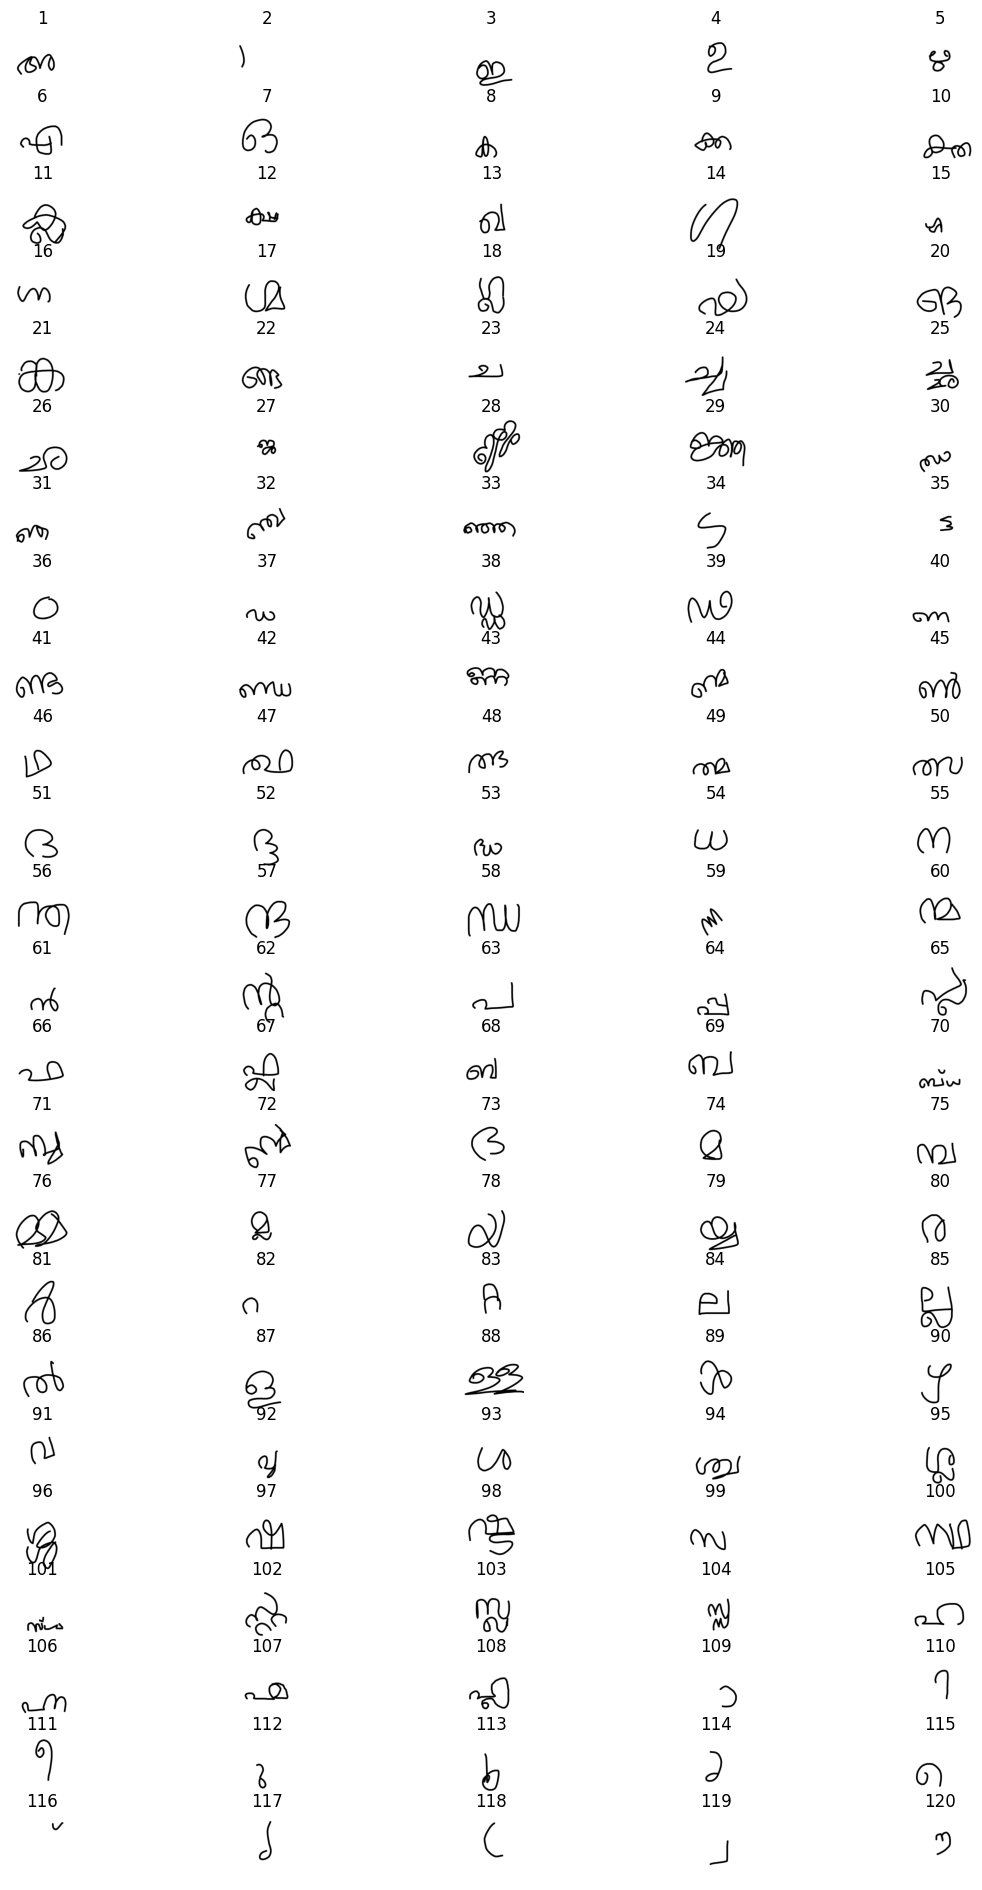

In [13]:
plt.rcParams['figure.figsize'] = [14,24]
fig, axs = plt.subplots(24,5)
for i in range(24):
    for j in range(5):
        letter=letters[i][j]
        try: 
            first=glob.glob(letter+"/*.png")[0]
        except:
            print(i,j)
        l=os.path.basename(letter)
        img=iio.imread(first)
        
        #img=cv2.resize(img, (1024,1024), interpolation = cv2.INTER_LINEAR)
        axs[i,j].imshow(img)
        axs[i,j].set_title(5*i+j+1)
        axs[i,j].axis('off')
plt.show()

In [91]:
import zipfile

zip_path = "/jupyter/aswin.vs/TrOCR_KAN/archive (16).zip"
extract_to = "/jupyter/aswin.vs/TrOCR_KAN/fixed_2"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_to)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [14]:
snd_fold=sorted(glob.glob("fixed_2/*"))

In [15]:
print(len(snd_fold))

48


In [16]:
snd_fold_re=np.reshape(snd_fold,(8,6))

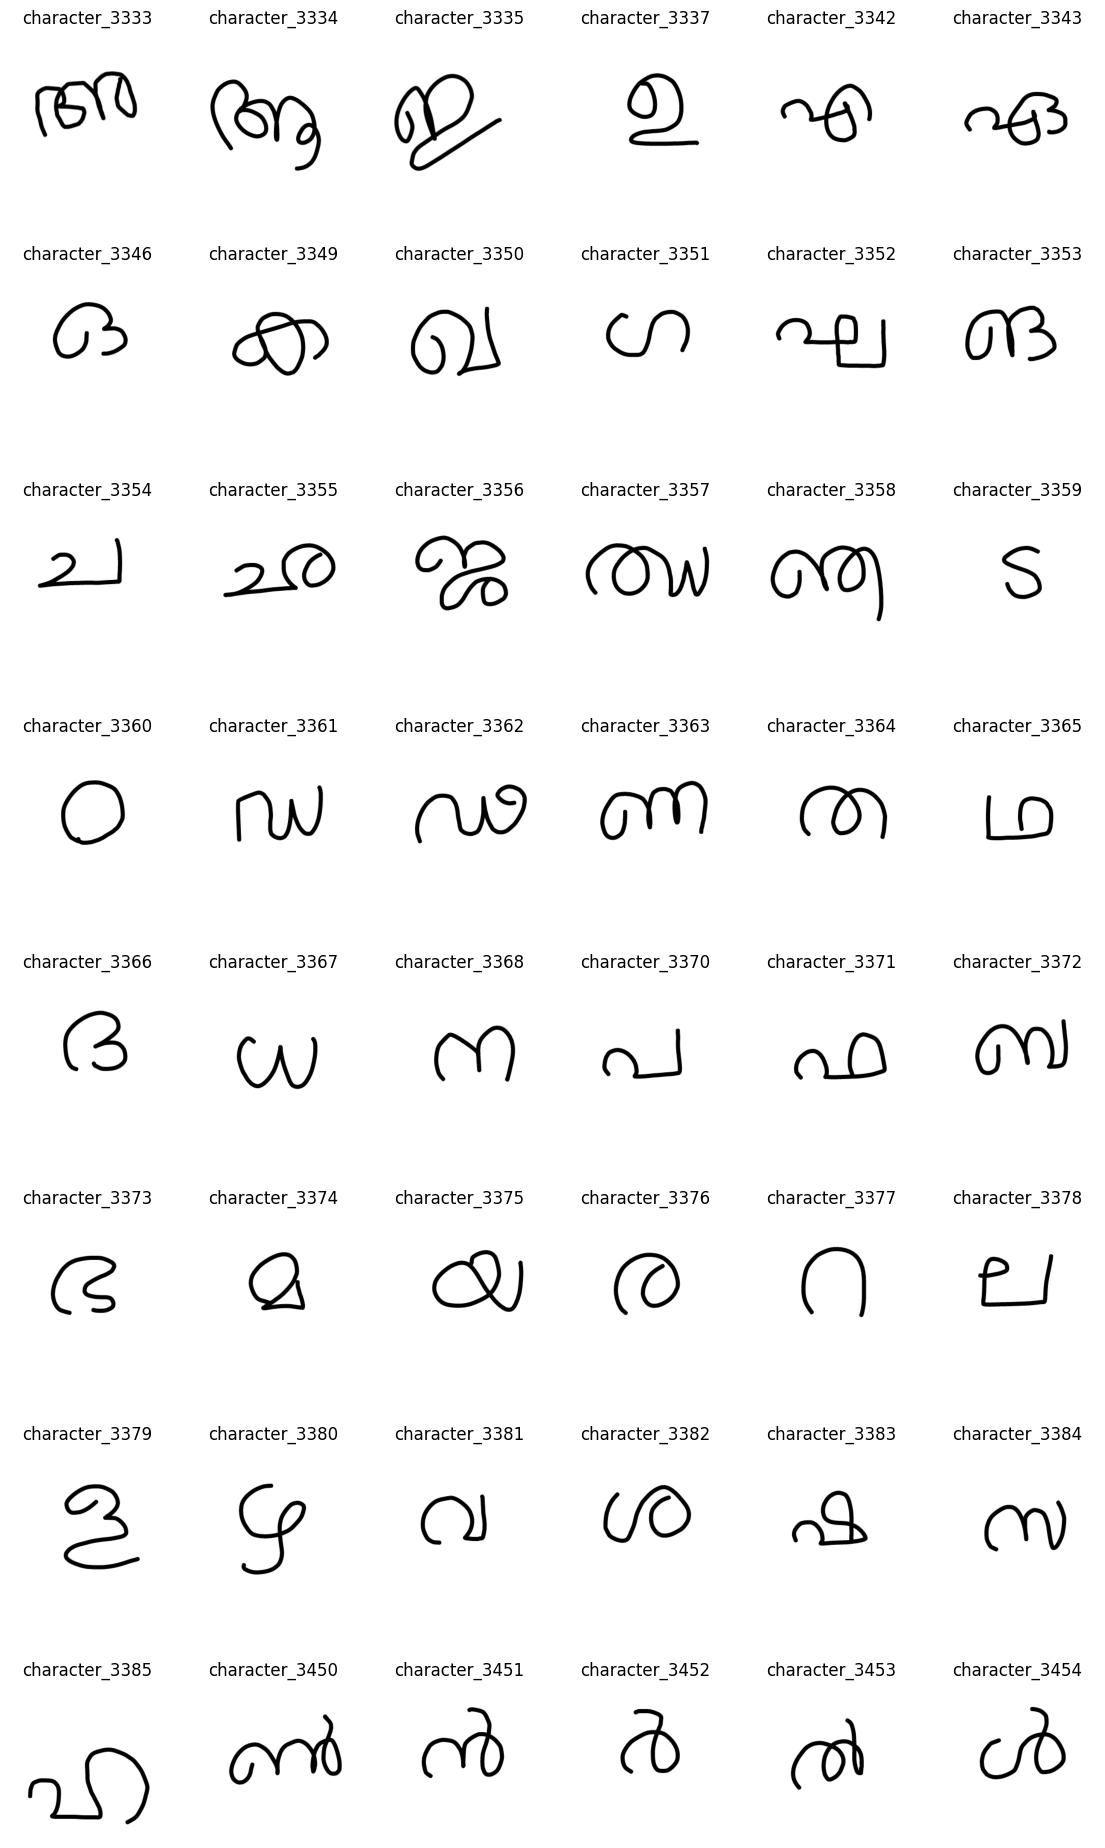

In [17]:
plt.rcParams['figure.figsize'] = [14,24]
fig, axs = plt.subplots(8,6)
for i in range(8):
    for j in range(6):
        letter=snd_fold_re[i][j]
        first=glob.glob(letter+"/*.png")[0]
        l=os.path.basename(letter)
        img=iio.imread(first)
        
        #img=cv2.resize(img, (1024,1024), interpolation = cv2.INTER_LINEAR)
        axs[i,j].imshow(img)
        axs[i,j].set_title(l)
        axs[i,j].axis('off')
plt.show()

In [18]:
letter_dict={}
for letter in snd_fold:
    letter_dict[letter]=""
    

In [19]:
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3333']="0"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3334']="1"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3335']="2"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3337']="3"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3342']="5"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3343']="6"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3346']="7"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3349']="8"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3350']="13"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3351']="14"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3352']="19"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3353']="20"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3354']="23"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3355']="26"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3356']="27"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3357']="51"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3358']="31"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3359']="34"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3360']="36"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3361']="37"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3362']="39"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3363']="40"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3364']="46"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3365']="52"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3366']="53"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3367']="56"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3368']="57"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3370']="66"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3371']="69"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3372']="71"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3373']="76"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3374']="77"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3375']="81"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3376']="83"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3377']="85"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3378']="87"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3379']="90"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3380']="93"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3381']="94"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3382']="96"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3383']="100"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3384']="102"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3385']="108"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3450']="45"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3451']="64"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3452']="84"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3453']="89"
letter_dict['/jupyter/aswin.vs/TrOCR_KAN/fixed_2/character_3454']="92"

In [100]:
for k in tqdm(letter_dict.keys()):
    save_path="/jupyter/aswin.vs/TrOCR_KAN/dataset"+letter_dict[k]
    imgs=sorted(glob.glob(k+"/*.png"))
    for img_name in imgs:
        img = cv2.imread(img_name,flags=cv2.IMREAD_UNCHANGED)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2BGRA)
        img=img[:,:,3]
        img=img/255.0
        img=np.where(img>0.5,1,0)
        if len(np.unique(img))<2:
            continue
        cv2.imwrite(save_path+"/new"+str(imgs.index(img_name))+".png",img)

100%|██████████| 96/96 [00:16<00:00,  5.89it/s]


In [101]:
splitfolders.ratio('/jupyter/aswin.vs/TrOCR_KAN/dataset', output="output", seed=1337, ratio=(0.7, 0.2,0.1))

Copying files: 5506 files [00:01, 2761.21 files/s]


In [20]:
def preprocessing_fun(img):
    img=np.where(img>0.5,1,0)
    return img

In [28]:
pip install torch torchvision torchaudio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [21]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch

# Preprocessing function
def preprocessing_fun(img):
    img = torch.where(img > 0.5, 1.0, 0.0)
    return img

# Training transforms
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128, 128)),
    transforms.RandomAffine(
        degrees=20,
        translate=(0.2, 0.2),
        shear=20,
        scale=(0.8, 1.2)
    ),
    transforms.ToTensor(),
    transforms.Lambda(preprocessing_fun)
])

# Validation transforms (no augmentation)
val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Lambda(preprocessing_fun)
])

# Load datasets
train_dataset = datasets.ImageFolder(
    root="/jupyter/aswin.vs/TrOCR_KAN/output/train",
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    root="/jupyter/aswin.vs/TrOCR_KAN/output/val",
    transform=val_transform
)

# Create dataloaders
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2
)

print("Number of training classes:", len(train_dataset.classes))
print("Class mapping:", train_dataset.class_to_idx)

Number of training classes: 119
Class mapping: {'0': 0, '1': 1, '10': 2, '100': 3, '101': 4, '102': 5, '103': 6, '104': 7, '105': 8, '106': 9, '107': 10, '108': 11, '109': 12, '11': 13, '110': 14, '111': 15, '112': 16, '113': 17, '114': 18, '115': 19, '116': 20, '117': 21, '118': 22, '12': 23, '13': 24, '14': 25, '15': 26, '16': 27, '17': 28, '18': 29, '19': 30, '2': 31, '20': 32, '21': 33, '22': 34, '23': 35, '24': 36, '25': 37, '26': 38, '27': 39, '28': 40, '29': 41, '3': 42, '30': 43, '31': 44, '32': 45, '33': 46, '34': 47, '35': 48, '36': 49, '37': 50, '38': 51, '39': 52, '4': 53, '40': 54, '41': 55, '42': 56, '43': 57, '44': 58, '45': 59, '46': 60, '47': 61, '48': 62, '49': 63, '5': 64, '50': 65, '51': 66, '52': 67, '53': 68, '54': 69, '55': 70, '56': 71, '57': 72, '58': 73, '59': 74, '6': 75, '60': 76, '61': 77, '62': 78, '63': 79, '64': 80, '65': 81, '66': 82, '67': 83, '68': 84, '69': 85, '7': 86, '70': 87, '71': 88, '72': 89, '73': 90, '74': 91, '75': 92, '76': 93, '77': 94, '

In [22]:
class_labels = train_dataset.classes

In [23]:
class_labels

['0',
 '1',
 '10',
 '100',
 '101',
 '102',
 '103',
 '104',
 '105',
 '106',
 '107',
 '108',
 '109',
 '11',
 '110',
 '111',
 '112',
 '113',
 '114',
 '115',
 '116',
 '117',
 '118',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '2',
 '20',
 '21',
 '22',
 '23',
 '24',
 '25',
 '26',
 '27',
 '28',
 '29',
 '3',
 '30',
 '31',
 '32',
 '33',
 '34',
 '35',
 '36',
 '37',
 '38',
 '39',
 '4',
 '40',
 '41',
 '42',
 '43',
 '44',
 '45',
 '46',
 '47',
 '48',
 '49',
 '5',
 '50',
 '51',
 '52',
 '53',
 '54',
 '55',
 '56',
 '57',
 '58',
 '59',
 '6',
 '60',
 '61',
 '62',
 '63',
 '64',
 '65',
 '66',
 '67',
 '68',
 '69',
 '7',
 '70',
 '71',
 '72',
 '73',
 '74',
 '75',
 '76',
 '77',
 '78',
 '79',
 '8',
 '80',
 '81',
 '82',
 '83',
 '84',
 '85',
 '86',
 '87',
 '88',
 '89',
 '9',
 '90',
 '91',
 '92',
 '93',
 '94',
 '95',
 '96',
 '97',
 '98',
 '99']

In [32]:
pip install torch torchvision torchaudio

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
!pip install pykan

Defaulting to user installation because normal site-packages is not writeable


In [24]:
import torch
import torch.nn as nn

from kan import KAN        # Real B-spline KAN implementation

class CNN_KAN(nn.Module):

    def __init__(self, num_classes=119):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(1, 6, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(6, 8, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(8, 16, kernel_size=5),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )

        self.flatten = nn.Flatten()

        self.kan = KAN(
            width=[16*12*12, 120, 84, num_classes],
            grid=5,
            k=3
        )

    def forward(self, x):

        x = self.features(x)

        x = self.flatten(x)

        x = self.kan(x)

        return x

In [25]:
model = CNN_KAN(num_classes=119)
print(model)

checkpoint directory created: ./model
saving model version 0.0
CNN_KAN(
  (features): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 8, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(8, 16, kernel_size=(5, 5), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (kan): MultKAN(
    (act_fun): ModuleList(
      (0-2): 3 x KANLayer(
        (base_fun): SiLU()
      )
    )
    (base_fun): SiLU()
    (symbolic_fun): ModuleList(
      (0-2): 3 x Symbolic_KANLayer()
    )
  )
)


In [27]:
import torch
import torch.nn as nn
from tqdm import tqdm

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Model
model = CNN_KAN(num_classes=119).to(device)

# Loss
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Epochs
num_epochs = 20

Using device: cuda
checkpoint directory created: ./model
saving model version 0.0


In [29]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 1, 128, 128])
torch.Size([64])


In [30]:
images = images.to(device)
labels = labels.to(device)

In [31]:
outputs = model(images)
print(outputs.shape)

torch.Size([64, 119])


In [ ]:
for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{num_epochs}",
        leave=True
    )

    for images, labels in progress_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{100 * correct / total:.2f}%"
        )

    train_loss = running_loss / len(train_loader)
    train_acc = 100 * correct / total

    print("-" * 50)
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Training Loss : {train_loss:.4f}")
    print(f"Training Acc  : {train_acc:.2f}%")
    print("-" * 50)

Epoch 1/20:  35%|███▌      | 21/60 [1:40:16<3:07:01, 287.73s/it, acc=1.26%, loss=4.7803]